# **Ejemplo de sobreajuste y subajuste**

Carlos Francisco Montoya Urzua

20 de Marzo de 2026

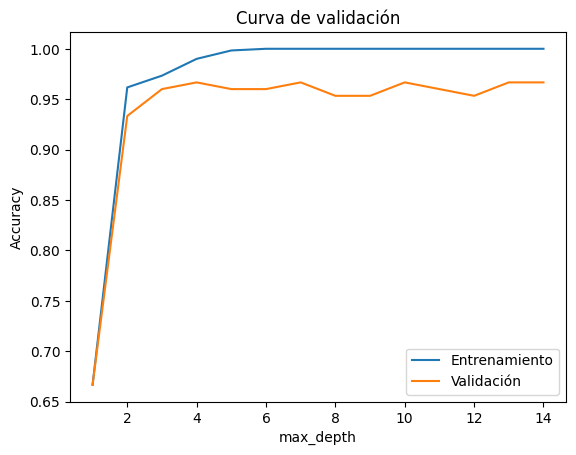

In [1]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve
#from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# Datos
X, y = load_iris(return_X_y=True)

# Modelo
model = DecisionTreeClassifier()

# Rango del hiperparámetro
param_range = np.arange(1, 15)

# Calcular curvas
train_scores, val_scores = validation_curve(
    model,
    X,
    y,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    scoring="accuracy"
)

# Promedios
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Gráfica
plt.figure()
plt.plot(param_range, train_mean, label="Entrenamiento")
plt.plot(param_range, val_mean, label="Validación")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Curva de validación")
plt.legend()
plt.show()

Con redes neuronales

In [2]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Datos
X, y = load_iris(return_X_y=True)

# División train/validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2)

# Modelo simple
model = keras.Sequential([
    keras.layers.Dense(16, activation='relu', input_shape=(4,)),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenamiento
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    verbose=0
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Graficacion

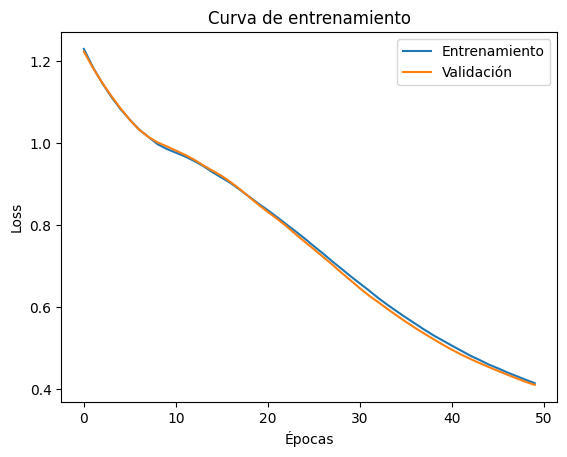

In [3]:
plt.figure()

plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')

plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.title("Curva de entrenamiento")
plt.legend()

plt.show()

Graficaicon del accuracy

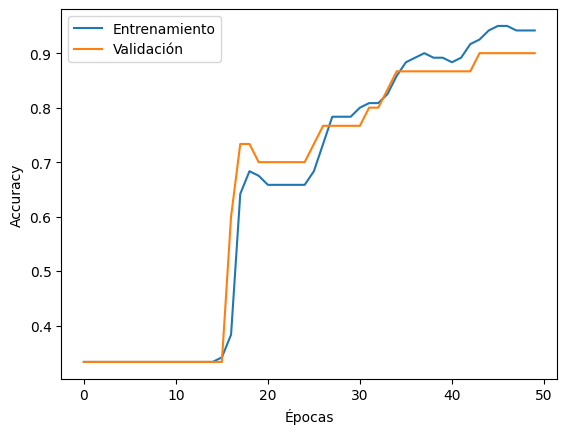

In [4]:
plt.figure()

plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')

plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

Si hay overfitting

Soluciones:

Regularización

keras.layers.Dense(16, activation='relu', kernel_regularizer='l2')

Dropout

keras.layers.Dropout(0.5)

Early stopping (MUY importante)

callback = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

Detiene el entrenamiento cuando empieza el sobreajuste

Si hay underfitting

Soluciones:

Aumentar neuronas o capas

Entrenar más épocas

Cambiar arquitectura